In [14]:
import sqlite3 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("../data/nhanes.db")

df = pd.read_sql("""
SELECT *
FROM analysis
WHERE activity_met_min_week IS NOT NULL
    AND bmi < 87
    AND implausible = 0
""", conn)

print(len(df))
df[["crp", "hba1c", "activity_met_min_week", "age", "bmi"]].describe()


4999


,crp,hba1c,activity_met_min_week,age,bmi
count,4999.000000,4999.000000,4999.000000,4999.000000,4999.000000
mean,4.127283,5.832286,4233.129026,49.858172,29.770954
std,8.030146,1.074849,6747.485256,18.516977,7.441171
min,0.110000,4.100000,0.000000,18.000000,14.200000
25%,0.880000,5.300000,0.000000,34.000000,24.700000
50%,1.940000,5.600000,1440.000000,52.000000,28.500000
75%,4.450000,6.000000,5040.000000,64.000000,33.600000
max,182.820000,16.200000,49680.000000,80.000000,86.200000


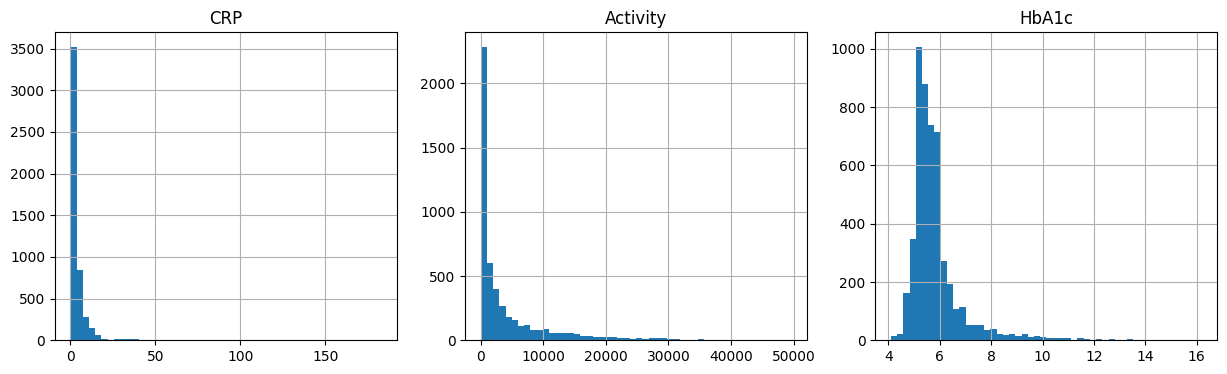

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df["crp"].hist(bins=50, ax=axes[0]); axes[0].set_title("CRP")
df["activity_met_min_week"].hist(bins=50, ax=axes[1]); axes[1].set_title("Activity")
df["hba1c"].hist(bins=50, ax=axes[2]); axes[2].set_title("HbA1c")
plt.show()

0.11


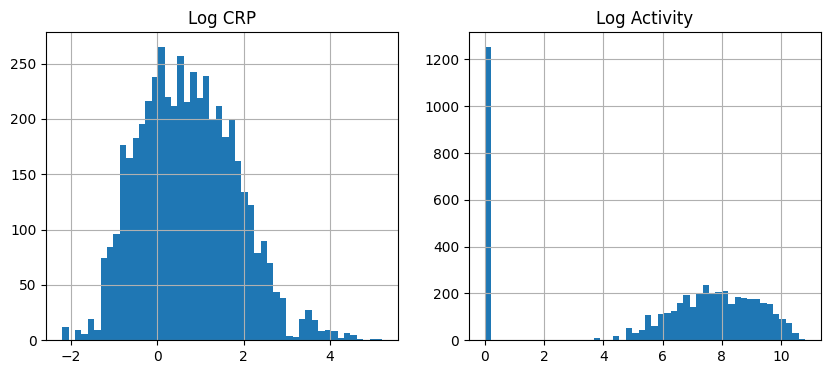

In [3]:
print(df["crp"].min())

df["log_crp"] = np.log(df["crp"])
df["log_activity"] = np.log1p(df["activity_met_min_week"])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df["log_crp"].hist(bins=50, ax=axes[0]); axes[0].set_title("Log CRP")
df["log_activity"].hist(bins=50, ax=axes[1]); axes[1].set_title("Log Activity")
plt.show()

In [4]:
df["activity_group"] = np.select(
    [df["activity_met_min_week"] == 0,
     df["activity_met_min_week"] < 600,
     df["activity_met_min_week"] < 1200],
     ["1_none", "2_below_guideline", "3_meet_guideline"],
     default = "4_well_above"
)
print((df["activity_group"] == 0).mean())
print(df["activity_group"].value_counts().sort_index())

0.0
activity_group
1_none               1253
2_below_guideline     613
3_meet_guideline      488
4_well_above         2645
Name: count, dtype: int64


In [5]:
import statsmodels.formula.api as smf

m1 = smf.ols("log_crp ~ C(activity_group)", data=df).fit()
print(m1.summary().tables[1])

                                             coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------
Intercept                                  0.8702      0.032     27.613      0.000       0.808       0.932
C(activity_group)[T.2_below_guideline]    -0.0848      0.055     -1.542      0.123      -0.193       0.023
C(activity_group)[T.3_meet_guideline]     -0.1626      0.060     -2.732      0.006      -0.279      -0.046
C(activity_group)[T.4_well_above]         -0.2458      0.038     -6.425      0.000      -0.321      -0.171


In [6]:
# Effects of activity below and meeting guidline could simply be noise because their interval contains zero
m2 = smf.ols("log_crp ~ C(activity_group) + age + C(sex) + bmi", data = df).fit()
print(m2.summary().tables[1])

                                             coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------
Intercept                                 -1.4374      0.076    -18.792      0.000      -1.587      -1.287
C(activity_group)[T.2_below_guideline]    -0.0543      0.048     -1.129      0.259      -0.148       0.040
C(activity_group)[T.3_meet_guideline]     -0.0610      0.052     -1.172      0.241      -0.163       0.041
C(activity_group)[T.4_well_above]         -0.1222      0.035     -3.504      0.000      -0.191      -0.054
C(sex)[T.male]                            -0.1615      0.028     -5.759      0.000      -0.216      -0.107
age                                        0.0037      0.001      4.797      0.000       0.002       0.005
bmi                                        0.0713      0.002     38.372      0.000       0.068       0.075


In [7]:
terms = [t for t in m1.params.index if "activity_group" in t]
ci = m2.conf_int()

comparison = pd.DataFrame({
    "unadjusted_%diff": (np.exp(m1.params[terms]) - 1) * 100,
    "adjusted_%diff":   (np.exp(m2.params[terms]) - 1) * 100,
    "adj_ci_low":       (np.exp(ci.loc[terms, 0]) - 1) * 100,
    "adj_ci_high":      (np.exp(ci.loc[terms, 1]) - 1) * 100,
}).round(1)

print(comparison)

                                        unadjusted_%diff  adjusted_%diff  \
C(activity_group)[T.2_below_guideline]              -8.1            -5.3   
C(activity_group)[T.3_meet_guideline]              -15.0            -5.9   
C(activity_group)[T.4_well_above]                  -21.8           -11.5   

                                        adj_ci_low  adj_ci_high  
C(activity_group)[T.2_below_guideline]       -13.8          4.1  
C(activity_group)[T.3_meet_guideline]        -15.1          4.2  
C(activity_group)[T.4_well_above]            -17.3         -5.2  


In [8]:
# Does BMI actually differ by activity group in your data?
print(df.groupby("activity_group")["bmi"].mean().round(1))

activity_group
1_none               30.3
2_below_guideline    30.0
3_meet_guideline     29.2
4_well_above         29.5
Name: bmi, dtype: float64


In [9]:
# Same model, without BMI
m3 = smf.ols("log_crp ~ C(activity_group) + age + C(sex)", data=df).fit()

terms = [t for t in m1.params.index if "activity_group" in t]
pd.DataFrame({
    "unadjusted_%diff":      (np.exp(m1.params[terms]) - 1) * 100,
    "no_BMI_adjust_%diff":   (np.exp(m3.params[terms]) - 1) * 100,
    "with_BMI_%diff":        (np.exp(m2.params[terms]) - 1) * 100,
}).round(1)


#Shows that crp is -22% less with high activity, but gender and age show that
# high activity only responsible for -14.9% and then BMI shows it's really only
# -11.5% which is still significant


,unadjusted_%diff,no_BMI_adjust_%diff,with_BMI_%diff
C(activity_group)[T.2_below_guideline],-8.1,-7.3,-5.3
C(activity_group)[T.3_meet_guideline],-15.0,-12.5,-5.9
C(activity_group)[T.4_well_above],-21.8,-14.9,-11.5


In [10]:
h1 = smf.ols("hba1c ~ C(activity_group)", data=df).fit()
h2 = smf.ols("hba1c ~ C(activity_group) + age + C(sex)", data=df).fit()
h3 = smf.ols("hba1c ~ C(activity_group) + age + C(sex) + bmi", data=df).fit()

terms = [t for t in h1.params.index if "activity_group" in t]
pd.DataFrame({
    "unadjusted":      h1.params[terms],
    "age_sex":         h2.params[terms],
    "age_sex_bmi":     h3.params[terms],
    "p_value_final":   h3.pvalues[terms],
}).round(3)

,unadjusted,age_sex,age_sex_bmi,p_value_final
C(activity_group)[T.2_below_guideline],-0.040,0.010,0.018,0.713
C(activity_group)[T.3_meet_guideline],-0.080,-0.022,0.004,0.936
C(activity_group)[T.4_well_above],-0.318,-0.136,-0.122,0.001


In [11]:
df["cluster"] = df["strata"] * 10 + df["psu"]
print(df["cluster"].nunique())

30


In [12]:
w2 = smf.wls(
    "log_crp ~ C(activity_group) + age + C(sex) + bmi",
    data=df,
    weights=df["weight"]
).fit(cov_type="cluster", cov_kwds={"groups": df["cluster"]})

terms = [t for t in w2.params.index if "activity_group" in t]
ci = w2.conf_int()

pd.DataFrame({
    "unweighted_%diff": (np.exp(m2.params[terms]) - 1) * 100,
    "weighted_%diff":   (np.exp(w2.params[terms]) - 1) * 100,
    "weighted_ci_low":  (np.exp(ci.loc[terms, 0]) - 1) * 100,
    "weighted_ci_high": (np.exp(ci.loc[terms, 1]) - 1) * 100,
    "weighted_p":       w2.pvalues[terms],
}).round(2)

,unweighted_%diff,weighted_%diff,weighted_ci_low,weighted_ci_high,weighted_p
C(activity_group)[T.2_below_guideline],-5.28,-2.35,-13.95,10.81,0.71
C(activity_group)[T.3_meet_guideline],-5.92,0.72,-13.40,17.14,0.93
C(activity_group)[T.4_well_above],-11.50,-16.16,-25.61,-5.52,0.00


In [13]:
hw = smf.wls(
    "hba1c ~ C(activity_group) + age + C(sex) + bmi",
    data=df,
    weights=df["weight"]
).fit(cov_type="cluster", cov_kwds={"groups": df["cluster"]})

terms = [t for t in hw.params.index if "activity_group" in t]
ci = hw.conf_int()

pd.DataFrame({
    "unweighted": h3.params[terms],
    "weighted": hw.params[terms],
    "weighted_ci_low": ci.loc[terms, 0],
    "weighted_ci_high": ci.loc[terms, 1],
    "weighted_p": hw.pvalues[terms],
    }).round(3)


,unweighted,weighted,weighted_ci_low,weighted_ci_high,weighted_p
C(activity_group)[T.2_below_guideline],0.018,-0.109,-0.255,0.038,0.147
C(activity_group)[T.3_meet_guideline],0.004,-0.097,-0.195,0.001,0.052
C(activity_group)[T.4_well_above],-0.122,-0.166,-0.248,-0.084,0.000
